# Word Embeddings: Meaning in Numbers
**COMP 395 — Deep Learning | In-Class Activity**

In this notebook you will:
1. Load pre-trained GloVe word embeddings and inspect a single vector
2. Measure word similarity with cosine similarity
3. Test the famous king − man + woman ≈ queen analogy (and poke at it)
4. Visualize embeddings in 2D with PCA
5. Explore gender bias in word embeddings
6. Load GloVe into `nn.Embedding` — the bridge to your RNN lab

---

## Setup

Run `pip install gensim` in your **torch environment** before starting (it's on slide 1). The first run downloads ~66 MB of GloVe vectors and may take a minute.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import gensim.downloader as api

# Load GloVe vectors (50 dimensions, trained on Wikipedia + Gigaword)
print("Loading GloVe embeddings (this may take a minute)...")
glove = api.load("glove-wiki-gigaword-50")
print(f"Loaded {len(glove)} word vectors, each with {glove.vector_size} dimensions.")

Loading GloVe embeddings (this may take a minute)...
Loaded 400000 word vectors, each with 50 dimensions.


---
## Part 1: What Does a Single Embedding Look Like?

Remember: `nn.Embedding` is a lookup table. Given an integer index, it returns a dense vector.  
GloVe works the same way — given a *word*, it returns a vector of 50 floats.

In [2]:
# Look up the embedding for a single word
word = "queen"
vec = glove[word]

print(f"Word: '{word}'")
print(f"Shape: {vec.shape}")
print(f"Type: {type(vec)}")
print(f"\nFirst 10 values: {vec[:10]}")
print(f"Min: {vec.min():.3f}, Max: {vec.max():.3f}, Mean: {vec.mean():.3f}")

Word: 'queen'
Shape: (50,)
Type: <class 'numpy.ndarray'>

First 10 values: [ 0.37854   1.8233   -1.2648   -0.1043    0.35829   0.60029  -0.17538
  0.83767  -0.056798 -0.75795 ]
Min: -2.284, Max: 1.823, Mean: -0.034


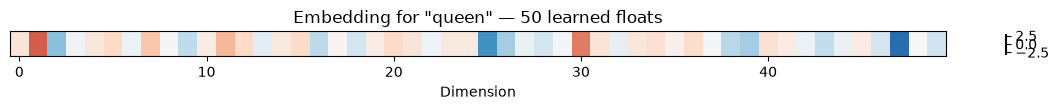

In [3]:
# Visualize the embedding as a heatmap
fig, ax = plt.subplots(figsize=(12, 1.2))
im = ax.imshow(vec.reshape(1, -1), cmap="RdBu_r", aspect="auto", vmin=-3, vmax=3)
ax.set_xlabel("Dimension")
ax.set_yticks([])
ax.set_title(f'Embedding for "{word}" — 50 learned floats', fontsize=12)
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

**Quick check:** No single dimension means "royalty" or "gender." The meaning is *distributed* across all 50 numbers. This is why we call them *distributed representations*.

---
## Part 2: Cosine Similarity

How do we measure whether two words are similar? We use **cosine similarity** — the cosine of the angle between two vectors:

$$\text{cos}(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\| \; \|\mathbf{b}\|}$$

- Close to **1** → very similar
- Close to **0** → unrelated
- Close to **-1** → opposite

In [4]:
def cosine_similarity(a, b):
    """Compute cosine similarity between two vectors."""
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# Try some word pairs
pairs = [
    ("cat", "dog"),
    ("cat", "car"),
    ("king", "queen"),
    ("king", "pizza"),
    ("happy", "sad"),
    ("happy", "joyful"),
]

print(f"{'Word Pair':<25} {'Cosine Similarity':>18}")
print("-" * 45)
for w1, w2 in pairs:
    sim = cosine_similarity(glove[w1], glove[w2])
    print(f"{w1 + ' ↔ ' + w2:<25} {sim:>18.4f}")

Word Pair                  Cosine Similarity
---------------------------------------------
cat ↔ dog                             0.9218
cat ↔ car                             0.3638
king ↔ queen                          0.7839
king ↔ pizza                          0.2204
happy ↔ sad                           0.6891
happy ↔ joyful                        0.5550


**Look closely:** `happy ↔ sad` scores *higher* than `happy ↔ joyful`. Opposites aren't negative — they're often among the most similar pairs!

**Discuss with your partner:** Using the distributional hypothesis, why would *happy* and *sad* end up close together? (Hint: what words appear around each of them?)

In [5]:
# gensim has a built-in method — find the most similar words
print("Words most similar to 'python':")
for word, score in glove.most_similar("python", topn=8):
    print(f"  {word:<15} {score:.4f}")

Words most similar to 'python':
  reticulated     0.6916
  spamalot        0.6636
  php             0.6414
  owl             0.6301
  mouse           0.6275
  reticulatus     0.6274
  perl            0.6268
  monkey          0.6207


**Try it yourself:** Pick 2–3 word pairs and check their similarity. Any surprises?

In [6]:
# YOUR EXPLORATION HERE
# Example: cosine_similarity(glove["YOUR_WORD"], glove["OTHER_WORD"])


### Aside: Calibrating Your Intuition

When you see a cosine similarity of 0.5, is that high or low? To answer that, we need a **baseline**.

In high-dimensional spaces, random directions are almost always **nearly orthogonal** (cosine similarity ≈ 0). This is called **concentration of measure** — for random unit vectors in $\mathbb{R}^d$, the expected cosine similarity is 0 with variance $1/d$. At $d = 50$ the standard deviation is only ~0.14.

But real embeddings aren't random directions — trained embedding spaces are **anisotropic** (word vectors share some common directions). So we compare against two baselines: random vectors, and random pairs of *real* words.

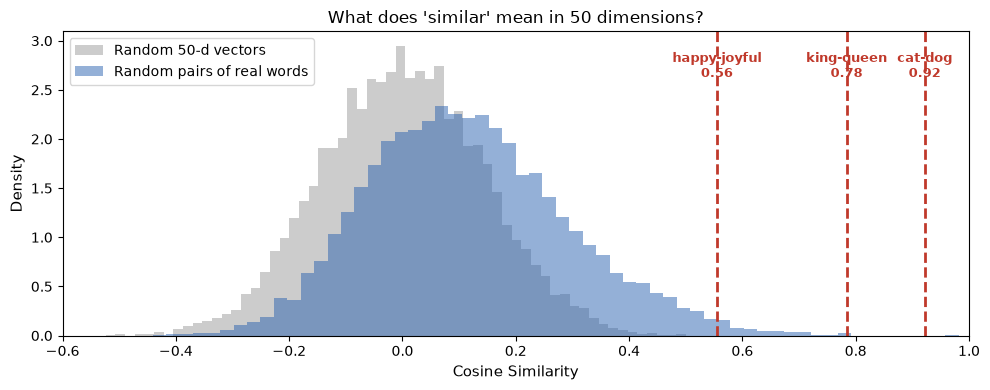

Random vectors:     mean = 0.001, std = 0.142  (theory: 0, 0.141)
Random real words:  mean = 0.116, std = 0.177


In [7]:
# Baseline 1: random 50-d unit vectors
rng = np.random.default_rng(42)
d = 50
n_pairs = 10_000

a = rng.standard_normal((n_pairs, d))
b = rng.standard_normal((n_pairs, d))
a = a / np.linalg.norm(a, axis=1, keepdims=True)
b = b / np.linalg.norm(b, axis=1, keepdims=True)
random_sims = (a * b).sum(axis=1)

# Baseline 2: random pairs of real (common) words from GloVe
common = glove.vectors[:20_000]
common = common / np.linalg.norm(common, axis=1, keepdims=True)
i = rng.integers(0, len(common), n_pairs)
j = rng.integers(0, len(common), n_pairs)
keep = i != j
word_sims = (common[i[keep]] * common[j[keep]]).sum(axis=1)

# Real related pairs to compare
real_pairs = [("cat", "dog"), ("king", "queen"), ("happy", "joyful")]
real_sims = [cosine_similarity(glove[w1], glove[w2]) for w1, w2 in real_pairs]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(random_sims, bins=60, density=True, alpha=0.6, color="#AAAAAA", label="Random 50-d vectors")
ax.hist(word_sims, bins=60, density=True, alpha=0.5, color="#2A62B0", label="Random pairs of real words")
for (w1, w2), sim in zip(real_pairs, real_sims):
    ax.axvline(sim, color="#C0392B", linewidth=2, linestyle="--")
    ax.text(sim, ax.get_ylim()[1] * 0.85, f"{w1}-{w2}\n{sim:.2f}",
            ha="center", fontsize=9, fontweight="bold", color="#C0392B")
ax.set_xlabel("Cosine Similarity", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.set_title("What does 'similar' mean in 50 dimensions?", fontsize=12)
ax.legend(fontsize=10, loc="upper left")
ax.set_xlim(-0.6, 1.0)
plt.tight_layout()
plt.show()

print(f"Random vectors:     mean = {random_sims.mean():.3f}, std = {random_sims.std():.3f}  (theory: 0, {1/np.sqrt(d):.3f})")
print(f"Random real words:  mean = {word_sims.mean():.3f}, std = {word_sims.std():.3f}")


**Takeaway:** Random real words already sit a little above 0, so judge similarities against *that* baseline, not against 0. Even so, related pairs like cat–dog are far out in the tail — not accidents.

> **Fine print for the math-curious:** Cosine similarity is not a proper distance metric — cosine *distance* ($1 - \cos$) doesn't satisfy the **triangle inequality** ($d(a,c) \leq d(a,b) + d(b,c)$). If you want a real metric, use angular distance ($\frac{1}{\pi}\arccos$). The triangle inequality is one of those things you prove in real analysis and then spend the rest of your career appreciating. Take real analysis.

---
## Part 3: Vector Arithmetic — The King–Queen Analogy

One of the most famous results from word embeddings:

$$\vec{\text{king}} - \vec{\text{man}} + \vec{\text{woman}} \approx \vec{\text{queen}}$$

The idea: subtracting "man" removes the male component, adding "woman" inserts the female component, and the royalty component stays.

In [8]:
# Manual vector arithmetic
result_vec = glove["king"] - glove["man"] + glove["woman"]

# What is the TRUE nearest word to this vector?
print("Nearest words to (king - man + woman), nothing excluded:")
for word, score in glove.similar_by_vector(result_vec, topn=3):
    print(f"  {word:<15} {score:.4f}")

# gensim's most_similar quietly EXCLUDES the input words (king, man, woman)
print("\nmost_similar(), which excludes the input words:")
for word, score in glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3):
    print(f"  {word:<15} {score:.4f}")


Nearest words to (king - man + woman), nothing excluded:
  king            0.8860
  queen           0.8610
  daughter        0.7685

most_similar(), which excludes the input words:
  queen           0.8524
  throne          0.7664
  prince          0.7592


**Surprise:** The nearest vector is still **king**! The classic result relies on excluding the input words. The analogy is real but weaker than it's usually presented (Nissim et al., 2020, *Fair is Better than Sensational*). Keep this in mind when we look at bias analogies in Part 5.

In [9]:
# Try more analogies!
analogies = [
    (["paris", "germany"], ["france"], "paris - france + germany = ?"),
    (["bigger", "cold"], ["big"], "bigger - big + cold = ?   (expected: colder)"),
]

for pos, neg, description in analogies:
    top3 = [w for w, _ in glove.most_similar(positive=pos, negative=neg, topn=3)]
    print(f"{description:<45} → {top3}")


paris - france + germany = ?                  → ['berlin', 'frankfurt', 'vienna']
bigger - big + cold = ?   (expected: colder)  → ['warmer', 'cooler', 'temperatures']


**Discuss:** `bigger − big + cold` gives *warmer* before *colder*. Connect this to the happy/sad surprise in Part 2 — why would an embedding confuse a word with its opposite?

**Try your own:** Write one analogy that works and one that fails.

In [10]:
# YOUR ANALOGIES HERE
# glove.most_similar(positive=[...], negative=[...], topn=3)


---
## Part 4: Visualizing Embeddings with PCA

50 dimensions is too many to visualize. We'll use **PCA** (which you already know!) to project down to 2D.

Remember: PCA finds the directions of maximum variance. We lose information, but the relative positions are approximately preserved.

In [11]:
# Choose semantically grouped words
word_groups = {
    "Animals":  ["cat", "dog", "fish", "bird", "horse"],
    "Royalty":  ["king", "queen", "prince", "princess", "throne"],
    "Tech":     ["computer", "software", "algorithm", "network", "data"],
    "Food":     ["pizza", "pasta", "bread", "rice", "salad"],
}

colors = {"Animals": "#2A62B0", "Royalty": "#E07020", "Tech": "#2E8B57", "Food": "#C0392B"}

# Collect all words and their vectors
all_words = []
all_vecs = []
all_labels = []
for group, words in word_groups.items():
    for w in words:
        all_words.append(w)
        all_vecs.append(glove[w])
        all_labels.append(group)

all_vecs = np.array(all_vecs)
print(f"Matrix shape: {all_vecs.shape}  (words × dimensions)")

Matrix shape: (20, 50)  (words × dimensions)


Variance explained: PC1=28.4%, PC2=23.3%


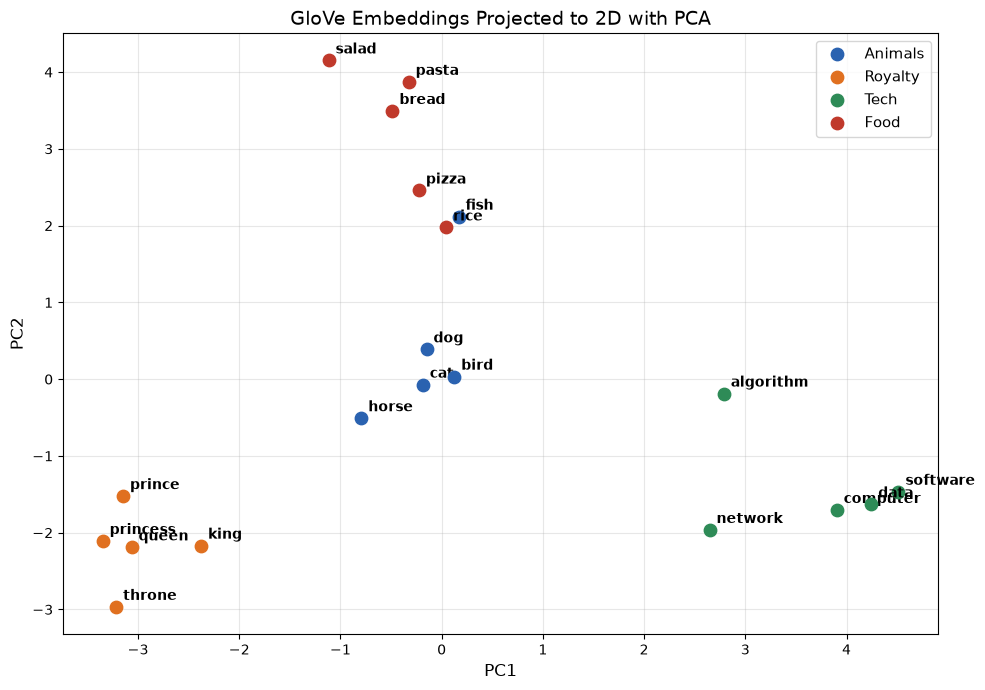

In [12]:
# PCA: 50 dims → 2 dims
pca = PCA(n_components=2)
coords = pca.fit_transform(all_vecs)

print(f"Variance explained: PC1={pca.explained_variance_ratio_[0]:.1%}, "
      f"PC2={pca.explained_variance_ratio_[1]:.1%}")

# Plot
fig, ax = plt.subplots(figsize=(10, 7))

for i, (word, group) in enumerate(zip(all_words, all_labels)):
    ax.scatter(coords[i, 0], coords[i, 1], color=colors[group], s=80, zorder=3)
    ax.annotate(word, (coords[i, 0], coords[i, 1]),
                fontsize=10, fontweight="bold",
                xytext=(5, 5), textcoords="offset points")

# Legend
for group, color in colors.items():
    ax.scatter([], [], color=color, s=80, label=group)
ax.legend(fontsize=11, loc="best")

ax.set_xlabel("PC1", fontsize=12)
ax.set_ylabel("PC2", fontsize=12)
ax.set_title("GloVe Embeddings Projected to 2D with PCA", fontsize=14)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Discuss with your partner:** Do the clusters make sense? Are any words positioned in unexpected places?

---
## Part 5: Bias in Word Embeddings

Bolukbasi et al. (2016) showed that Word2Vec embeddings trained on Google News encode gender stereotypes. The key insight: there is a **gender direction** in embedding space, and occupation words are not neutral along it.

We'll replicate a simplified version of their method on GloVe:
1. Normalize vectors (so we measure **direction**, just like cosine similarity)
2. Average the differences of several gendered pairs to get a stable gender direction
3. Project occupation words onto that direction

In [13]:
def unit(v):
    return v / np.linalg.norm(v)

# Step 1: A gender direction averaged over several definitional pairs
gender_pairs = [("she", "he"), ("her", "his"), ("woman", "man"), ("mother", "father"),
                ("girl", "boy"), ("daughter", "son"), ("herself", "himself"),
                ("female", "male"), ("sister", "brother")]

gender_direction = unit(np.mean([unit(glove[f]) - unit(glove[m]) for f, m in gender_pairs], axis=0))
print(f"Gender direction shape: {gender_direction.shape}")
print("Unit vector pointing from the 'male' words toward the 'female' words.")


Gender direction shape: (50,)
Unit vector pointing from the 'male' words toward the 'female' words.


In [14]:
# Step 2: Project (normalized) occupation words onto the gender direction
# Positive → closer to the "she" side, negative → closer to the "he" side
occupations = [
    "programmer", "engineer", "scientist", "doctor", "lawyer",
    "nurse", "teacher", "homemaker", "receptionist", "librarian",
    "architect", "surgeon", "pilot", "dancer", "secretary",
    "professor", "captain", "journalist", "hairdresser", "nanny",
]

projections = {occ: float(np.dot(unit(glove[occ]), gender_direction)) for occ in occupations}
sorted_occs = sorted(projections.items(), key=lambda x: x[1])

print(f"{'Occupation':<15} {'Projection':>10}   Direction")
print("-" * 45)
for occ, proj in sorted_occs:
    arrow = "← he " if proj < 0 else "she →"
    bar = "█" * int(abs(proj) * 60)
    print(f"{occ:<15} {proj:>10.3f}   {arrow} {bar}")


Occupation      Projection   Direction
---------------------------------------------
captain             -0.440   ← he  ██████████████████████████
architect           -0.336   ← he  ████████████████████
secretary           -0.243   ← he  ██████████████
engineer            -0.231   ← he  █████████████
scientist           -0.172   ← he  ██████████
lawyer              -0.172   ← he  ██████████
programmer          -0.153   ← he  █████████
professor           -0.148   ← he  ████████
pilot               -0.055   ← he  ███
surgeon             -0.045   ← he  ██
doctor              -0.024   ← he  █
journalist          -0.008   ← he  
teacher             -0.003   ← he  
librarian            0.066   she → ███
dancer               0.184   she → ███████████
hairdresser          0.246   she → ██████████████
nanny                0.275   she → ████████████████
nurse                0.299   she → █████████████████
homemaker            0.317   she → ███████████████████
receptionist         0.326   she → 

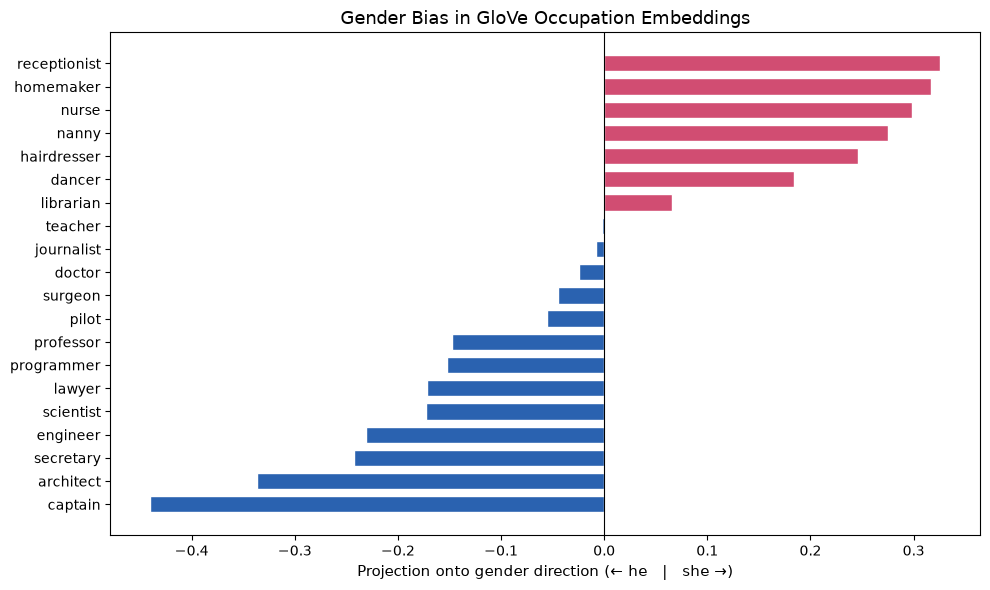

In [15]:
# Step 3: Visualize the bias
fig, ax = plt.subplots(figsize=(10, 6))

occs = [item[0] for item in sorted_occs]
projs = [item[1] for item in sorted_occs]
bar_colors = ["#2A62B0" if p < 0 else "#D14D72" for p in projs]

ax.barh(range(len(occs)), projs, color=bar_colors, edgecolor="white", height=0.7)
ax.set_yticks(range(len(occs)))
ax.set_yticklabels(occs, fontsize=10)
ax.set_xlabel("Projection onto gender direction (← he   |   she →)", fontsize=11)
ax.set_title("Gender Bias in GloVe Occupation Embeddings", fontsize=13)
ax.axvline(x=0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


### Reflection

These associations weren't programmed in — they were **learned from text**. The training corpus (Wikipedia, news) reflects societal patterns, and the embeddings absorb them.

**Discuss with your partner:**
- Which results match the stereotypes from the paper? Which surprised you?
- *secretary* leans toward **he** here. Why might that be in a news corpus? (Think: *Secretary of State*, *General Secretary*.) What does this tell you about one-vector-per-word?

---
## Part 6: Bridge to Your Lab — GloVe inside `nn.Embedding`

```
Text → tokens → integer indices → nn.Embedding → dense vectors → RNN
```

`nn.Embedding` is a learnable lookup table. Here we fill it with GloVe vectors so you can see it's the *same* object you'll train from scratch in the RNN lab.

In [16]:
import torch
import torch.nn as nn

# A tiny vocabulary: word → integer index
vocab = ["the", "cat", "sat", "on", "queen"]
word_to_idx = {w: i for i, w in enumerate(vocab)}

# Build the (vocab_size, embed_dim) weight matrix from GloVe
weights = torch.tensor(np.stack([glove[w] for w in vocab]))
embedding = nn.Embedding.from_pretrained(weights, freeze=True)
print("Weight matrix shape:", embedding.weight.shape, " (vocab_size, embed_dim)")

# Text → tokens → indices → vectors, with a batch of 2 sequences of length 3
batch = torch.tensor([[word_to_idx[w] for w in ["the", "cat", "sat"]],
                      [word_to_idx[w] for w in ["the", "queen", "sat"]]])
out = embedding(batch)
print("Input shape: ", batch.shape, " (batch, seq_len)")
print("Output shape:", out.shape, " (batch, seq_len, embed_dim)")

# Each row of the weight matrix IS a word's embedding
print("Row for 'queen' matches GloVe:", torch.allclose(out[1, 1], torch.tensor(glove["queen"])))


Weight matrix shape: torch.Size([5, 50])  (vocab_size, embed_dim)
Input shape:  torch.Size([2, 3])  (batch, seq_len)
Output shape: torch.Size([2, 3, 50])  (batch, seq_len, embed_dim)
Row for 'queen' matches GloVe: True


**Pre-trained vs. learned:** Here `freeze=True` keeps GloVe fixed. In your lab you'll create `nn.Embedding(vocab_size, embed_dim)` with **random** weights and let backprop shape them — just like the conv filters you trained in Lab 5.

---
## Exit Ticket

**Submit your answers before leaving class.**

1. A GloVe embedding for the word "pizza" is a vector of 50 floats. In one sentence, what does this vector *represent*?

2. Why is cosine similarity preferred over Euclidean distance for comparing word embeddings? (1–2 sentences)

3. If `nn.Embedding(10000, 64)` creates an embedding layer, what is the shape of its internal weight matrix? What does each *row* represent?

4. Give one concrete example of how bias in word embeddings could cause harm in a deployed system.